# Fig. S8: validation RMSE vs number of input features

Feature-count scan used to choose the encoder input size for each modality
(`figure1c` in `training_configuration.py`, reported in Table S4). Base DMM
(`EGFR_MAPK__logobs`) with the central ML hyperparameters, trained on feature
sets selected by recursive feature elimination (RFE; HVGRFE = RFE after a
highly-variable-feature prefilter) of size N = 4 … 4,096, plus the full
post-filter feature set (`all`). Five CV folds, each holding out one cell line
(BT20, HCC1500, HCC2185, MCF7, UACC3199), × 10 random starts.

The x-axis is the number of features that actually enter the encoder, which is
not always N:

* **HVGRFE** (MassSpec, RNAseq) selects from the 501 most variable features of
  the training lines, so every N ≥ 512 gives the same 501 inputs; those runs
  collapse to one point.
* **Multimodal** concatenates N selected features from each of CyTOF, MassSpec
  and RNAseq, i.e. 3N inputs.
* **`all`** is every feature that passes the missing-value filter (no RFE).

The same scan also trained RNAseq and MassSpec DMMs on 40 knowledge-based
feature sets: 6 published signatures (PAM50, IHC, CSC, MPAS, MEKFA, CompRes)
and 34 MSigDB pathway sets for EGFR, ERBB, MAPK, ERK, RAS and p38 signaling.
They are shown as separate points and compared with the data-driven sets
(panel C), but kept out of the scan curves, the summary table and Table S4.

Input: `eval/EGFR_MAPK__logobs/dream_cytof/evaluate_all_figure1c.csv` and the
PEtab measurement table in `data/`. Use the NEMO rerun finished on
21 Nov 2026: HVG prefilter without the low-mean step (50bd9e1), RNAseq at
6 latent dimensions (70ad8de), and the curated sets (f764986). Earlier files
predate these changes. The curated sets' feature counts are read from the
selected-feature files in `features/`.

The last section builds Table S4 (final hyperparameters per input modality)
from `training_configuration.py`.

In [1]:
import sys
from pathlib import Path

# Ensure project root is on sys.path
_project_root = str(
    next(
        (
            _p
            for _p in (Path.cwd(), *Path.cwd().parents)
            if (_p / "common.py").is_file()
        ),
        Path.cwd().parent,
    )
)
if _project_root not in sys.path:
    sys.path.insert(0, _project_root)

import ast
import importlib
import re
import warnings
from typing import Union

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from scipy import stats
from sklearn.impute import KNNImputer

warnings.filterwarnings("ignore")

import figures_paper.figure_config as figure_config
from common import (
    EVALUATE_ALL_CSVS,
    FEATURES_OUTFILE,
    Wildcards,
    training_samples,
    val_samples,
)
from dmm.config_options import Conf
from dmm.feature_selection import load_data, preprocess_mosa_latent
from generate_run_configs import generate_run_configs
from training_configuration import (
    BEST_FEATURE_SETS,
    CONTEXTS_FEATURES_1C,
    SPLITS_1C,
)
from util import load_petab_base_files

importlib.reload(figure_config)
from figures_paper.figure_config import (
    CONTEXT_COLORS,
    FONTSIZE,
    LW_MEDIUM,
    LW_THICK,
    LW_THIN,
    configure_axis_spines,
    get_context_label,
)

## Configuration

In [2]:
model = "EGFR_MAPK__logobs"
data = "dream_cytof"
figure = "figure1c"

CONTEXT_ORDER = ["cytof_init", "transcriptomics", "proteomics", "multimodal", "MOSA"]
SPLITS = sorted(SPLITS_1C)

# Contexts whose multimodal recipe concatenates N features per modality
# (select_features.build_context_feature_recipe)
MULTIMODAL_PARTS = ["cytof_init", "proteomics", "transcriptomics"]

SCAN_RE = re.compile(r"^(?P<method>HVGRFE|RFE)_(?P<N>\d+)_permute$")


def parse_n(features: str) -> int | None:
    m = SCAN_RE.match(features)
    return int(m["N"]) if m else None


# Knowledge-based feature sets (select_features.get_selected_features):
# published signatures and MSigDB pathway sets, for RNAseq and MassSpec
SIGNATURES = ["PAM50", "IHC", "CSC", "MPAS", "MEKFA", "CompRes"]
CURATED_CONTEXTS = ["transcriptomics", "proteomics"]


def curated_type(features: str) -> str | None:
    if features in SIGNATURES:
        return "signature"
    if features.startswith("MSIGDB_"):
        return "MSigDB"
    return None


# Hyperparameters each context is trained with in the main text: central
# values with per-context overrides, from the pipeline's own config generator
HYPERPARAMS = [
    "n_hidden",
    "depth",
    "dropout_rate",
    "l1reg_inflater_output",
    "l2reg_inflater_output",
    "nn_init_scale",
    "recon_loss",
    "inflater_output_reg_epoch",
    "n_epoch",
    "inflater_bound",
]
FINAL_CONFIGS = {
    c["context"]: c
    for c in generate_run_configs(
        contexts_features=list(BEST_FEATURE_SETS.items()),
        n_starts=1,
        select_central_values=True,
        splits=["all"],
    )
}

## Candidate features per modality and CV fold

Replicates `select_features.prepare_inputs_for_context` up to the selection
step: pivot of the PEtab measurement table (training lines only) → drop
features with ≥ 30 % missing values (`load_data`) → KNN imputation →
mean-centring → HVG prefilter (`get_hvg`, HVGRFE only).

In [3]:
# get_hvg lives in select_features.py, which runs fire.Fire() at import;
# load just that function so the counts use the pipeline's own code.
_src = (Path(_project_root) / "select_features.py").read_text()
_fn = next(
    n for n in ast.parse(_src).body
    if isinstance(n, ast.FunctionDef) and n.name == "get_hvg"
)
_ns = {"np": np, "pd": pd, "Union": Union}
exec(compile(ast.Module(body=[_fn], type_ignores=[]), "get_hvg", "exec"), _ns)
get_hvg = _ns["get_hvg"]

petab_base_files = load_petab_base_files(Conf(model=model, data=data))
del petab_base_files["condition_table"]
measurements = petab_base_files["measurement_table"]

count_rows = []
for split in SPLITS:
    wc = Wildcards(data, split)
    samples_train, samples_val = training_samples(wc), val_samples(wc)
    for context in ["cytof_init", "proteomics", "transcriptomics"]:
        omics = context in ("proteomics", "transcriptomics")
        if omics:
            raw = measurements[
                (measurements.measurementType == context)
                & (measurements.time == 0)
                & measurements.preequilibrationConditionId.isin(samples_train)
            ].FEATURE_ID.nunique()
        X, *_ = load_data(
            contextualization=context,
            samples=samples_train,
            features=None,
            **petab_base_files,
        )
        X = pd.DataFrame(KNNImputer().fit_transform(X), index=X.index, columns=X.columns)
        X -= X.mean()
        count_rows.append(
            dict(
                context=context,
                samples=split,
                n_train_lines=len(samples_train),
                n_raw=raw if omics else X.shape[1],
                n_all=X.shape[1],
                n_hvg=get_hvg(X).shape[1] if omics else np.nan,
            )
        )
    X_mosa, _, _ = preprocess_mosa_latent(
        Conf(model=model, data=data, context="MOSA", samples=split),
        samples_train,
        samples_val,
    )
    count_rows.append(
        dict(
            context="MOSA",
            samples=split,
            n_train_lines=len(X_mosa),
            n_raw=X_mosa.shape[1],
            n_all=X_mosa.shape[1],
            n_hvg=np.nan,
        )
    )

counts = pd.DataFrame(count_rows).set_index(["context", "samples"]).sort_index()
counts

n_train_lines  n_raw  n_all  n_hvg
context         samples                                     
MOSA            BT20                 45    200    200    NaN
                HCC1500              45    200    200    NaN
                HCC2185              46    200    200    NaN
                MCF7                 45    200    200    NaN
                UACC3199             46    200    200    NaN
cytof_init      BT20                 57     37     37    NaN
                HCC1500              57     37     37    NaN
                HCC2185              57     37     37    NaN
                MCF7                 57     37     37    NaN
                UACC3199             57     37     37    NaN
proteomics      BT20                 57   7874   6179  501.0
                HCC1500              57   7872   6177  501.0
                HCC2185              57   7873   6182  501.0
                MCF7                 57   7874   6187  501.0
                UACC3199             57   7874   6181  501.0
transcriptomics BT20                 57  16562  16562  501.0
                HCC1500              57  16562  16562  501.0
                HCC2185              57  16562  16562  501.0
                MCF7                 57  16562  16562  501.0
                UACC3199             57  16562  16562  501.0

In [4]:
# Raw feature counts over all cell lines in the measurement table, for reference
raw_all_lines = {
    context: measurements[
        (measurements.measurementType == context) & (measurements.time == 0)
    ]
    .groupby("FEATURE_ID")
    .preequilibrationConditionId.nunique()
    for context in ["proteomics", "transcriptomics"]
}
n_lines_all = {
    context: measurements[measurements.measurementType == context]
    .preequilibrationConditionId.nunique()
    for context in raw_all_lines
}
for context, per_feature in raw_all_lines.items():
    print(
        f"{context:16s}: {len(per_feature):,} features in the table, "
        f"{(per_feature == n_lines_all[context]).sum():,} measured in all "
        f"{n_lines_all[context]} lines"
    )
print()
print(
    counts.groupby("context")[["n_train_lines", "n_raw", "n_all", "n_hvg"]]
    .agg(["min", "median", "max"])
    .to_string()
)

proteomics      : 7,877 features in the table, 3,751 measured in all 67 lines
transcriptomics : 16,562 features in the table, 16,562 measured in all 64 lines

                n_train_lines             n_raw                  n_all                  n_hvg              
                          min median max    min   median    max    min   median    max    min median    max
context                                                                                                    
MOSA                       45   45.0  46    200    200.0    200    200    200.0    200    NaN    NaN    NaN
cytof_init                 57   57.0  57     37     37.0     37     37     37.0     37    NaN    NaN    NaN
proteomics                 57   57.0  57   7872   7874.0   7874   6177   6181.0   6187  501.0  501.0  501.0
transcriptomics            57   57.0  57  16562  16562.0  16562  16562  16562.0  16562  501.0  501.0  501.0


## Load scan evaluations

In [5]:
df = pd.read_csv(
    EVALUATE_ALL_CSVS.format(model=model, data=data, filename=f"evaluate_all_{figure}"),
    index_col=0,
)
dmm_val = df[(df.dataset == "val") & (df.ref == "DMM") & (df.model == model)].copy()

expected = {(c, f) for c, f in CONTEXTS_FEATURES_1C}
found = set(map(tuple, dmm_val[["context", "features"]].drop_duplicates().values))
print("Configured but missing from the evaluation:", sorted(expected - found) or "none")
print("Evaluated but not configured:", sorted(found - expected) or "none")

# Data-driven scan: RFE/HVGRFE sizes and `all`. The curated sets are analyzed
# separately below and stay out of the scan curves, summary and Table S4.
val = dmm_val.copy()
val["N"] = val["features"].map(parse_n)
val = val[val["N"].notna() | (val["features"] == "all")]


def n_inputs(row) -> int:
    """Number of features that enter the encoder for one run."""
    if row.context == "multimodal":
        return int(
            sum(
                min(row.N, counts.loc[(part, row.samples), "n_hvg"])
                if part != "cytof_init"
                else min(row.N, counts.loc[(part, row.samples), "n_all"])
                for part in MULTIMODAL_PARTS
            )
        )
    c = counts.loc[(row.context, row.samples)]
    if row.features == "all":
        return int(c.n_all)
    if row.features.startswith("HVGRFE"):
        return int(min(row.N, c.n_hvg))
    return int(min(row.N, c.n_all))


val["n_inputs"] = val.apply(n_inputs, axis=1)

# Runs per (context, feature set): expect 5 folds x 10 starts (MOSA: fewer folds,
# since not every held-out line has a MOSA embedding)
runs = val.groupby(["context", "features"]).agg(
    folds=("samples", "nunique"), runs=("rmse", "size"), n_inputs=("n_inputs", "median")
)
print(runs.sort_values(["context", "n_inputs"]).to_string())

Configured but missing from the evaluation: none
Evaluated but not configured: none
                                     folds  runs  n_inputs
context         features                                  
MOSA            RFE_4_permute            3    30       4.0
                RFE_6_permute            3    30       6.0
                RFE_8_permute            3    30       8.0
                RFE_10_permute           3    30      10.0
                RFE_12_permute           3    30      12.0
                RFE_16_permute           3    30      16.0
                RFE_20_permute           3    30      20.0
                RFE_24_permute           3    30      24.0
                RFE_28_permute           3    30      28.0
                RFE_32_permute           3    30      32.0
                RFE_64_permute           3    30      64.0
                RFE_128_permute          3    30     128.0
                all                      3    30     200.0
cytof_init      RFE_4_permute  

In [6]:
# Each context's scan runs must use the hyperparameters it is trained with;
# a stale CSV (e.g. RNAseq at 7 latent dimensions) would mix models here.
used = dmm_val.groupby("context")[HYPERPARAMS].agg(lambda s: sorted(s.unique()))
mismatch = {
    (context, hp): (values, FINAL_CONFIGS[context][hp])
    for context, row in used.iterrows()
    for hp, values in row.items()
    if values != [FINAL_CONFIGS[context][hp]]
}
assert not mismatch, f"Scan runs differ from the final hyperparameters: {mismatch}"
used

,n_hidden,depth,dropout_rate,l1reg_inflater_output,l2reg_inflater_output,nn_init_scale,recon_loss,inflater_output_reg_epoch,n_epoch,inflater_bound
context,,,,,,,,,,
MOSA,[6.0],[0.0],[0.1],[0.1],[0.0],[0.1],[0.01],[200.0],[500.0],[3.0]
cytof_init,[8.0],[1.0],[0.1],[0.1],[0.0],[0.1],[0.01],[200.0],[500.0],[3.0]
multimodal,[6.0],[0.0],[0.1],[0.1],[0.0],[0.1],[0.01],[200.0],[500.0],[3.0]
proteomics,[5.0],[1.0],[0.1],[0.1],[0.0],[0.1],[0.01],[200.0],[500.0],[3.0]
transcriptomics,[6.0],[1.0],[0.1],[0.1],[0.0],[0.1],[0.01],[200.0],[500.0],[3.0]


In [7]:
# Feature sets that resolve to the same inputs (HVGRFE N >= 512 -> 501 HVGs)
# must give the same result; keep the smallest N of each such group.
dup = (
    val.groupby(["context", "samples", "n_inputs", "job"])
    .agg(n_sets=("features", "nunique"), spread=("rmse", lambda x: x.max() - x.min()))
    .query("n_sets > 1")
)
print(f"{len(dup)} (context, fold, n_inputs, start) groups with >1 feature set; "
      f"max RMSE spread within a group: {dup.spread.max() if len(dup) else 0:.2e}")

keep = (
    val.assign(_order=val["N"].fillna(np.inf))
    .sort_values("_order")
    .groupby(["context", "n_inputs"])["features"]
    .first()
)
val = val.merge(keep.rename("keep").reset_index(), on=["context", "n_inputs"])
val = val[val["features"] == val["keep"]].drop(columns="keep")

100 (context, fold, n_inputs, start) groups with >1 feature set; max RMSE spread within a group: 0.00e+00


## Aggregate

Median over the 10 random starts within each fold, then mean ± SEM over folds.
Panel B uses the paired, per-fold difference to the selected feature-set size.

In [8]:
per_fold = (
    val.groupby(["context", "features", "N", "n_inputs", "samples"], dropna=False)
    .rmse.median()
    .reset_index()
)

selected = per_fold[
    per_fold.apply(lambda r: r.features == BEST_FEATURE_SETS[r.context], axis=1)
].set_index(["context", "samples"]).rmse
per_fold["delta"] = per_fold.rmse - per_fold.set_index(["context", "samples"]).index.map(selected)

# x position per (context, feature set): "all" for MassSpec varies by a few
# features across folds, so use the median count
summary = (
    per_fold.groupby(["context", "features"])
    .agg(
        n_inputs=("n_inputs", "median"),
        N=("N", "first"),
        rmse_mean=("rmse", "mean"),
        rmse_sem=("rmse", "sem"),
        delta_mean=("delta", "mean"),
        delta_sem=("delta", "sem"),
        folds=("rmse", "size"),
    )
    .reset_index()
    .sort_values(["context", "n_inputs"])
)
summary["is_selected"] = summary.apply(
    lambda r: r.features == BEST_FEATURE_SETS[r.context], axis=1
)
summary["is_all"] = summary.features == "all"

## Knowledge-based feature sets

Same metric as the scan: median over the 10 starts within each fold, then
mean ± SEM over folds. The feature count of a curated set is the number of its
genes or proteins that pass the missing-value filter in a fold's training
lines (columns of the selected-feature file), summarized as the median over
folds.

Each curated set is compared, paired per fold, with three data-driven sets of
the same modality:

* **selected:** the selected size (RNAseq HVGRFE_4, MassSpec HVGRFE_10);
* **size-matched:** the HVGRFE set nearest in size on a log scale, with
  HVGRFE_512 counting as 501 features;
* **all:** all features passing the missing-value filter.

In [9]:
def n_curated_features(context: str, split: str, features: str) -> int:
    """Number of selected features in a fold's training feature file."""
    path = FEATURES_OUTFILE.format(
        model=model, data=data, dataset="train",
        context=context, samples=split, features=features,
    )
    return pd.read_csv(path, index_col=0, nrows=0).shape[1]


cur = dmm_val[dmm_val.features.map(curated_type).notna()].copy()
cur["type"] = cur.features.map(curated_type)
assert set(cur.context) <= set(CURATED_CONTEXTS)
cur_fold = (
    cur.groupby(["context", "type", "features", "samples"]).rmse.median().reset_index()
)
cur_fold["n_features"] = [
    n_curated_features(r.context, r.samples, r.features) for r in cur_fold.itertuples()
]
print(
    cur_fold.groupby(["context", "type"]).features.nunique().to_string(),
    "\nfolds per set:", sorted(cur_fold.groupby(["context", "features"]).size().unique()),
)

ref_fold = per_fold.set_index(["context", "features", "samples"]).rmse
hvgrfe_sizes = {
    context: s[s.features.str.startswith("HVGRFE")].set_index("features").n_inputs
    for context, s in summary.groupby("context")
    if context in CURATED_CONTEXTS
}


def size_matched(context: str, n: float) -> str:
    sizes = hvgrfe_sizes[context]
    return (np.log(sizes) - np.log(n)).abs().idxmin()


REFERENCES = ["selected", "size_matched", "all"]
rows, cur_deltas = [], []
for (context, ctype, features), g in cur_fold.groupby(["context", "type", "features"]):
    g = g.set_index("samples")
    n_med = g.n_features.median()
    refs = {
        "selected": BEST_FEATURE_SETS[context],
        "size_matched": size_matched(context, n_med),
        "all": "all",
    }
    row = dict(
        modality=get_context_label(context),
        context=context,
        type=ctype,
        features=features,
        n_features_median=n_med,
        n_features_min=g.n_features.min(),
        n_features_max=g.n_features.max(),
        folds=len(g),
        rmse_mean=g.rmse.mean(),
        rmse_sem=g.rmse.sem(),
    )
    for ref, ref_features in refs.items():
        r = ref_fold.loc[(context, ref_features)].reindex(g.index)
        delta = g.rmse - r
        row |= {
            f"{ref}_features": ref_features,
            f"delta_{ref}_mean": delta.mean(),
            f"delta_{ref}_sem": delta.sem(),
            f"delta_{ref}_rel_pct": 100 * (g.rmse.mean() / r.mean() - 1),
            f"worse_than_{ref}": f"{(delta > 0).sum()}/{delta.notna().sum()}",
        }
        cur_deltas.append(
            pd.DataFrame(
                dict(context=context, type=ctype, features=features,
                     reference=ref, delta=delta)
            ).reset_index()
        )
    rows.append(row)

curated = pd.DataFrame(rows).sort_values(["context", "rmse_mean"]).reset_index(drop=True)
cur_deltas = pd.concat(cur_deltas, ignore_index=True)
curated.to_csv("figure_S8_curated_sets.csv", index=False)
curated[
    ["modality", "type", "features", "n_features_median", "rmse_mean",
     "delta_selected_rel_pct", "worse_than_selected", "size_matched_features",
     "delta_size_matched_rel_pct", "worse_than_size_matched", "delta_all_rel_pct"]
].round(3)

context          type     
proteomics       MSigDB       34
                 signature     6
transcriptomics  MSigDB       34
                 signature     6 
folds per set: [np.int64(5)]


,modality,type,features,n_features_median,rmse_mean,delta_selected_rel_pct,worse_than_selected,size_matched_features,delta_size_matched_rel_pct,worse_than_size_matched,delta_all_rel_pct
0,MassSpec,MSigDB,MSIGDB_BIOCARTA_ERK,15.0,0.678,-8.489,2/5,HVGRFE_16_permute,-21.379,1/5,-15.795
1,MassSpec,MSigDB,MSIGDB_PID_ERBB,31.0,0.734,-0.864,2/5,HVGRFE_32_permute,-10.623,2/5,-8.779
2,MassSpec,MSigDB,MSIGDB_KEGG_ERK,16.0,0.740,-0.099,3/5,HVGRFE_16_permute,-14.171,2/5,-8.075
3,MassSpec,MSigDB,MSIGDB_REACTOME_ERBB2,27.0,0.774,4.459,2/5,HVGRFE_28_permute,-1.366,3/5,-3.881
4,MassSpec,MSigDB,MSIGDB_KEGG_EGFR,13.0,0.784,5.792,4/5,HVGRFE_12_permute,4.404,4/5,-2.654
...,...,...,...,...,...,...,...,...,...,...,...
75,RNAseq,MSigDB,MSIGDB_BIOCARTA_RAS,22.0,0.913,53.488,4/5,HVGRFE_24_permute,36.178,4/5,20.782
76,RNAseq,MSigDB,MSIGDB_PID_P38,26.0,0.922,54.943,5/5,HVGRFE_28_permute,37.515,5/5,21.927
77,RNAseq,MSigDB,MSIGDB_BIOCARTA_P38,36.0,0.929,56.254,5/5,HVGRFE_32_permute,36.420,5/5,22.959
78,RNAseq,MSigDB,MSIGDB_BIOCARTA_MAPK,81.0,0.929,56.282,5/5,HVGRFE_64_permute,26.368,5/5,22.980


In [10]:
# Per modality: how the curated sets compare with each data-driven reference
agg = []
for context, c in curated.groupby("context"):
    for ref in REFERENCES:
        rel = c[f"delta_{ref}_rel_pct"]
        agg.append(
            dict(
                modality=get_context_label(context),
                reference=ref,
                sets=len(c),
                worse_on_average=int((c[f"delta_{ref}_mean"] > 0).sum()),
                worse_in_all_folds=int(
                    c[f"worse_than_{ref}"].map(lambda s: s.split("/")[0] == s.split("/")[1]).sum()
                ),
                median_rel_pct=rel.median(),
                min_rel_pct=rel.min(),
                max_rel_pct=rel.max(),
            )
        )
curated_agg = pd.DataFrame(agg)
display(curated_agg.round(1))
best = curated.loc[curated.groupby("context").rmse_mean.idxmin()]
display(best[["modality", "features", "n_features_median", "rmse_mean", "rmse_sem",
              "delta_selected_mean", "delta_selected_sem", "worse_than_selected"]].round(3))

,modality,reference,sets,worse_on_average,worse_in_all_folds,median_rel_pct,min_rel_pct,max_rel_pct
0,MassSpec,selected,40,37,12,16.7,-8.5,37.9
1,MassSpec,size_matched,40,33,3,8.1,-21.4,36.6
2,MassSpec,all,40,34,5,7.4,-15.8,26.9
3,RNAseq,selected,40,40,33,33.0,6.7,72.2
4,RNAseq,size_matched,40,33,8,12.5,-5.9,50.4
5,RNAseq,all,40,29,10,4.6,-16.0,35.5


,modality,features,n_features_median,rmse_mean,rmse_sem,delta_selected_mean,delta_selected_sem,worse_than_selected
0,MassSpec,MSIGDB_BIOCARTA_ERK,15.0,0.678,0.071,-0.063,0.095,2/5
40,RNAseq,MSIGDB_REACTOME_ERBB2_CANCER,25.0,0.635,0.060,0.040,0.057,3/5


## Plot

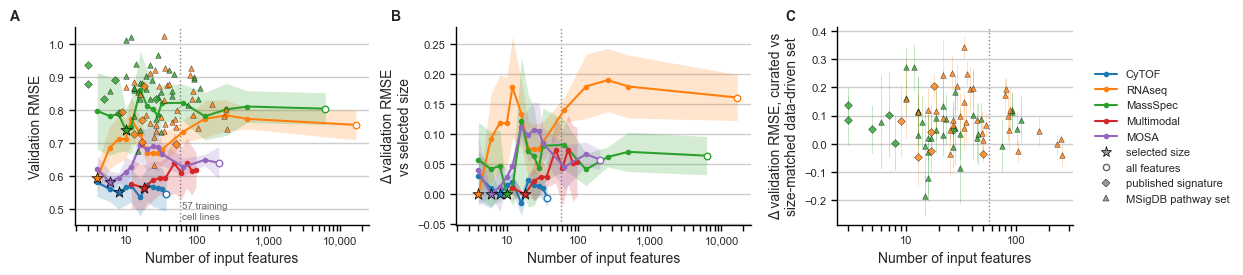

In [11]:
N_TRAIN_LINES = int(counts.n_train_lines.loc[["cytof_init"]].iloc[0])

CURATED_MARKERS = {"signature": "D", "MSigDB": "^"}

fig, axes = plt.subplots(
    1, 3, figsize=(10.8, 2.8), gridspec_kw={"width_ratios": [1, 1, 0.8]}
)
axes[1].sharex(axes[0])

for ax, (y, yerr, ylabel) in zip(
    axes[:2],
    [
        ("rmse_mean", "rmse_sem", "Validation RMSE"),
        ("delta_mean", "delta_sem", "Δ validation RMSE\nvs selected size"),
    ],
):
    for context in CONTEXT_ORDER:
        s = summary[summary.context == context].sort_values("n_inputs")
        if s.empty:
            continue
        color = CONTEXT_COLORS[get_context_label(context)]
        ax.fill_between(
            s.n_inputs, s[y] - s[yerr], s[y] + s[yerr], color=color, alpha=0.2, lw=0
        )
        ax.plot(
            s.n_inputs, s[y], color=color, lw=LW_THICK, marker="o", ms=3,
            label=get_context_label(context),
        )
        a = s[s.is_all]
        ax.scatter(a.n_inputs, a[y], s=22, facecolor="white", edgecolor=color,
                   linewidth=LW_MEDIUM, zorder=4)
        b = s[s.is_selected]
        ax.scatter(b.n_inputs, b[y], s=70, marker="*", facecolor=color,
                   edgecolor="black", linewidth=LW_THIN, zorder=5)

    ax.axvline(N_TRAIN_LINES, color="0.5", ls=":", lw=LW_MEDIUM, zorder=0)
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(mticker.LogLocator(base=10))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.set_xlabel("Number of input features")
    ax.set_ylabel(ylabel)
    configure_axis_spines(ax)

# A: knowledge-based sets as single points at their median feature count
for (context, ctype), c in curated.groupby(["context", "type"]):
    axes[0].scatter(
        c.n_features_median, c.rmse_mean, s=16, marker=CURATED_MARKERS[ctype],
        facecolor=CONTEXT_COLORS[get_context_label(context)], edgecolor="black",
        linewidth=0.3, alpha=0.8, zorder=3,
    )

# C: paired per-fold difference to the size-matched data-driven set
ax = axes[2]
for (context, ctype), c in curated.groupby(["context", "type"]):
    ax.errorbar(
        c.n_features_median, c.delta_size_matched_mean, yerr=c.delta_size_matched_sem,
        fmt="none", ecolor=CONTEXT_COLORS[get_context_label(context)],
        elinewidth=LW_THIN, alpha=0.35, zorder=2,
    )
    ax.scatter(
        c.n_features_median, c.delta_size_matched_mean, s=16,
        marker=CURATED_MARKERS[ctype],
        facecolor=CONTEXT_COLORS[get_context_label(context)], edgecolor="black",
        linewidth=0.3, alpha=0.8, zorder=3,
    )
ax.axhline(0, color="black", lw=LW_THIN, zorder=0)
ax.axvline(N_TRAIN_LINES, color="0.5", ls=":", lw=LW_MEDIUM, zorder=0)
ax.set_xscale("log")
ax.xaxis.set_major_locator(mticker.LogLocator(base=10))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Number of input features")
ax.set_ylabel("Δ validation RMSE, curated vs\nsize-matched data-driven set")
configure_axis_spines(ax)

axes[1].axhline(0, color="black", lw=LW_THIN, zorder=0)
axes[0].text(
    N_TRAIN_LINES * 1.08, 0.02, f"{N_TRAIN_LINES} training\ncell lines",
    transform=axes[0].get_xaxis_transform(), va="bottom", fontsize=FONTSIZE - 1, color="0.4",
)

handles, labels = axes[0].get_legend_handles_labels()
handles += [
    Line2D([], [], ls="", marker="*", ms=8, mfc="0.6", mec="black", mew=LW_THIN),
    Line2D([], [], ls="", marker="o", ms=4.5, mfc="white", mec="0.4", mew=LW_MEDIUM),
    Line2D([], [], ls="", marker="D", ms=4, mfc="0.6", mec="black", mew=0.3),
    Line2D([], [], ls="", marker="^", ms=4.5, mfc="0.6", mec="black", mew=0.3),
]
labels += ["selected size", "all features", "published signature", "MSigDB pathway set"]
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
for ax, letter in zip(axes, "ABC"):
    ax.text(-0.22, 1.02, letter, transform=ax.transAxes, fontweight="bold",
            fontsize=FONTSIZE + 2, va="bottom")
fig.tight_layout()
fig.savefig("figure_S8.pdf", bbox_inches="tight")
fig.savefig("figure_S8.png", dpi=300, bbox_inches="tight")
plt.show()

## Checks for the Methods / response text

* Size with the lowest mean validation RMSE per modality, and how far it is
  from the selected size.
* RMSE at the largest feature set relative to the best one, with the number of
  folds in which the largest set is worse than the selected one.
* Spearman correlation between log(number of inputs) and mean RMSE across all
  tested sizes.

In [12]:
rows = []
for context in CONTEXT_ORDER:
    s = summary[summary.context == context].sort_values("n_inputs")
    if s.empty:
        continue
    best = s.loc[s.rmse_mean.idxmin()]
    sel = s[s.is_selected].iloc[0]
    largest = s.iloc[-1]
    pf_largest = per_fold[(per_fold.context == context) & (per_fold.features == largest.features)]
    rho, p = stats.spearmanr(np.log(s.n_inputs), s.rmse_mean)
    rows.append(
        dict(
            modality=get_context_label(context),
            sizes_tested=len(s),
            n_range=f"{s.n_inputs.min():,.0f}–{s.n_inputs.max():,.0f}",
            selected=f"{sel.features} ({sel.n_inputs:,.0f} inputs)",
            best=f"{best.features} ({best.n_inputs:,.0f} inputs)",
            rmse_best=best.rmse_mean,
            rmse_selected=sel.rmse_mean,
            rmse_largest=largest.rmse_mean,
            largest_vs_best_pct=100 * (largest.rmse_mean / best.rmse_mean - 1),
            max_vs_best_pct=100 * (s.rmse_mean.max() / best.rmse_mean - 1),
            folds_largest_worse=f"{(pf_largest.delta > 0).sum()}/{len(pf_largest)}",
            spearman_rho=rho,
            spearman_p=p,
        )
    )
checks = pd.DataFrame(rows).set_index("modality")
checks.round(3)

,sizes_tested,n_range,selected,best,rmse_best,rmse_selected,rmse_largest,largest_vs_best_pct,max_vs_best_pct,folds_largest_worse,spearman_rho,spearman_p
modality,,,,,,,,,,,,
CyTOF,11,4–37,RFE_8_permute (8 inputs),RFE_16_permute (16 inputs),0.536,0.552,0.546,1.758,8.435,1/5,-0.336,0.312
RNAseq,15,"4–16,562",HVGRFE_4_permute (4 inputs),HVGRFE_4_permute (4 inputs),0.595,0.595,0.756,27.079,31.954,5/5,0.579,0.024
MassSpec,15,"4–6,181",HVGRFE_10_permute (10 inputs),HVGRFE_10_permute (10 inputs),0.741,0.741,0.805,8.677,16.395,5/5,0.379,0.164
Multimodal,10,12–96,RFE_6_permute (18 inputs),RFE_6_permute (18 inputs),0.566,0.566,0.620,9.581,13.150,4/5,0.818,0.004
MOSA,13,4–200,RFE_6_permute (6 inputs),RFE_6_permute (6 inputs),0.583,0.583,0.641,9.918,19.084,3/3,0.505,0.078


In [13]:
table = summary.assign(modality=summary.context.map(get_context_label))[
    ["modality", "features", "N", "n_inputs", "folds", "rmse_mean", "rmse_sem",
     "delta_mean", "delta_sem", "is_selected"]
]
table.to_csv("figure_S8_scan_summary.csv", index=False)
table.round(4)

,modality,features,N,n_inputs,folds,rmse_mean,rmse_sem,delta_mean,delta_sem,is_selected
8,MOSA,RFE_4_permute,4.0,4.0,3,0.6226,0.0396,0.0396,0.0586,False
10,MOSA,RFE_6_permute,6.0,6.0,3,0.5830,0.0332,0.0000,0.0000,True
11,MOSA,RFE_8_permute,8.0,8.0,3,0.5955,0.0145,0.0125,0.0418,False
0,MOSA,RFE_10_permute,10.0,10.0,3,0.6119,0.0446,0.0289,0.0119,False
2,MOSA,RFE_12_permute,12.0,12.0,3,0.6296,0.0213,0.0466,0.0139,False
...,...,...,...,...,...,...,...,...,...,...
60,RNAseq,HVGRFE_64_permute,64.0,64.0,5,0.7355,0.0333,0.1408,0.0207,False
50,RNAseq,HVGRFE_128_permute,128.0,128.0,5,0.7741,0.0563,0.1794,0.0538,False
55,RNAseq,HVGRFE_256_permute,256.0,256.0,5,0.7848,0.0470,0.1900,0.0526,False
59,RNAseq,HVGRFE_512_permute,512.0,501.0,5,0.7741,0.0306,0.1793,0.0523,False


## Table S4: final hyperparameters per input modality

One row per input modality, with the feature set and ML hyperparameters used
for the main-text DMMs (`BEST_FEATURE_SETS` and the central values in
`training_configuration.py`). The last column gives the feature scan's
validation RMSE at the selected size (mean ± SEM over folds of the median
over 10 starts).

In [14]:
selected_rows = summary[summary.is_selected].set_index("context")


def n_candidates(context: str, features: str) -> int:
    """Median number of features that enter selection, over CV folds."""
    if context == "multimodal":
        return int(
            counts.loc["cytof_init"].n_all.median()
            + counts.loc["proteomics"].n_hvg.median()
            + counts.loc["transcriptomics"].n_hvg.median()
        )
    c = counts.loc[context]
    return int(c.n_hvg.median() if features.startswith("HVGRFE") else c.n_all.median())


rows = []
for context in CONTEXT_ORDER:
    cfg, features = FINAL_CONFIGS[context], BEST_FEATURE_SETS[context]
    s = selected_rows.loc[context]
    rows.append(
        {
            "Input": get_context_label(context),
            "Feature set": features,
            "Features per modality": parse_n(features),
            "Encoder inputs": int(s.n_inputs),
            "Candidate features": n_candidates(context, features),
            "Latent dimensions": cfg["n_hidden"],
            "Hidden layers": cfg["depth"],
            "Dropout rate": cfg["dropout_rate"],
            "L1 penalty on parameter deviations": cfg["l1reg_inflater_output"],
            "L1 penalty until epoch": cfg["inflater_output_reg_epoch"],
            "L2 penalty on parameter deviations": cfg["l2reg_inflater_output"],
            "Parameter deviation bound": cfg["inflater_bound"],
            "Weight initialization scale": cfg["nn_init_scale"],
            "Reconstruction loss weight": cfg["recon_loss"],
            "Epochs": cfg["n_epoch"],
            "Validation RMSE at selected size": (
                f"{s.rmse_mean:.3f} ± {s.rmse_sem:.3f} ({s.folds} folds)"
            ),
        }
    )
table_s4 = pd.DataFrame(rows)
table_s4.to_csv("final_hyperparameters_per_context.csv", index=False)
table_s4.T

,0,1,2,3,4
Input,CyTOF,RNAseq,MassSpec,Multimodal,MOSA
Feature set,RFE_8_permute,HVGRFE_4_permute,HVGRFE_10_permute,RFE_6_permute,RFE_6_permute
Features per modality,8,4,10,6,6
Encoder inputs,8,4,10,18,6
Candidate features,37,501,501,1039,200
Latent dimensions,8,6,5,6,6
Hidden layers,1,1,1,0,0
Dropout rate,0.1,0.1,0.1,0.1,0.1
L1 penalty on parameter deviations,0.1,0.1,0.1,0.1,0.1
L1 penalty until epoch,200,200,200,200,200
